# Summarize abundance results

In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

In [2]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"

## 1. Count assayed genes and alleles from median and mean calculation

In [3]:
abun_median = pl.read_csv(f'{dualipa_outputs}/DUALIPA_median_zscore.csv', infer_schema_length=1000000).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele")
).filter(~pl.col("zscore_log2").is_null()).rename(
    {"zscore_log2": "zscore_log2fc_median_norm_by_each_wt"}
)

num_alleles = len(abun_median.select("gene_allele").to_series().unique().to_list())
num_genes = len(abun_median.select("symbol").to_series().unique().to_list())
print(f"{num_alleles} variants across {num_genes} genes were assayed for aggregation by median.")

741 variants across 87 genes were assayed for aggregation by median.


In [4]:
abun_mean = pl.read_csv(f'{dualipa_outputs}/DUALIPA_mean_zscore.csv', infer_schema_length=1000000).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele"),
).filter(
    ~pl.col("zscore_log2").is_null()
).rename(
    {
        "allele_wt_log2fc_zscore": "zscore_log2fc_mean_norm_by_all_wt_mean",
        "zscore_log2": "zscore_log2fc_mean_norm_by_each_wt"
    }
)

num_alleles = len(abun_mean.select("gene_allele").to_series().unique().to_list())
num_genes = len(abun_mean.select("symbol").to_series().unique().to_list())
print(f"{num_alleles} variants across {num_genes} genes were assayed for aggregation by mean.")

763 variants across 93 genes were assayed for aggregation by mean.


__Mean calculation preserved more genes and variants, since the WT median might more likely be zero.__

## 2. Investigate impact of log2 Z-score vs. fold-change z-score

The first set of results were z-scores computed based on raw GFP:mCherry ratios. However, the raw ratios are highly skewed and it makes more sense to do the analysis on log-transformed ratios (log2FC). Here we investigate the impact of using a raw ratio vs. a log2FC. 

### 2.1 Median case

In [5]:
pDEST_DUAL_allele_df = abun_median.to_pandas()
sig_threshold = 1.96

clean_array = pDEST_DUAL_allele_df['zscore_median'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_median_norm_by_each_wt'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

Percentage of sig zscore values: 8.50%
Percentage of sig increase: 1.89%
Percentage of sig decrease: 6.61%
Percentage of sig zscore_log2 values: 35.49%
Percentage of sig increase: 2.16%
Percentage of sig decrease: 33.33%


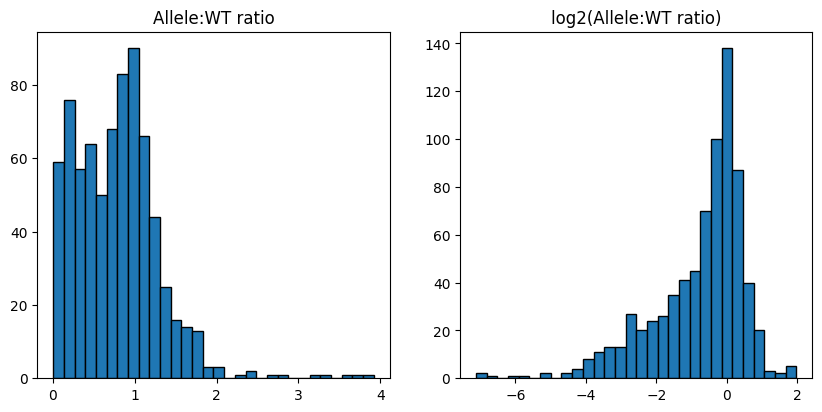

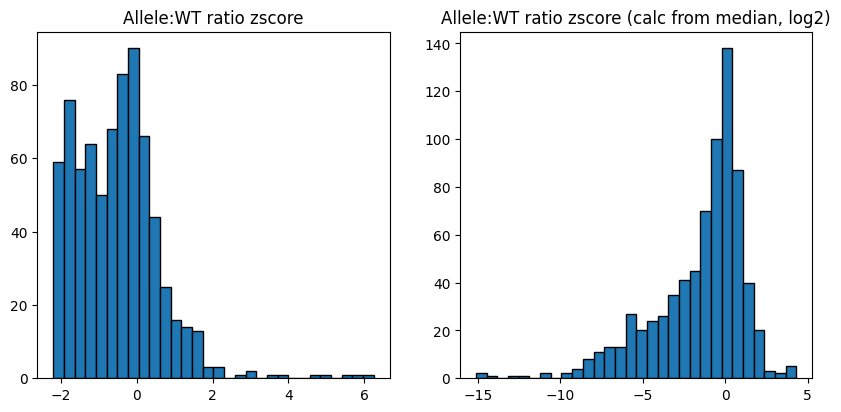

In [6]:
fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['allele_wt_ratio_median'], bins=30, edgecolor='black')
axes[0].set_title("Allele:WT ratio")

axes[1].hist(np.log2(pDEST_DUAL_allele_df['allele_wt_ratio_median']), bins=30, edgecolor='black')
axes[1].set_title("log2(Allele:WT ratio)")
plt.show()

fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['zscore_median'], bins=30, edgecolor='black')
axes[0].set_title("Allele:WT ratio zscore")

axes[1].hist(pDEST_DUAL_allele_df['zscore_log2fc_median_norm_by_each_wt'], bins=30, edgecolor='black')
axes[1].set_title("Allele:WT ratio zscore (calc from median, log2)")
plt.show()

### 2.2 Mean case

Percentage of sig zscore_log2 values: 51.51%
Percentage of sig increase: 8.26%
Percentage of sig decrease: 43.25%
Percentage of sig zscore_log2 values: 33.81%
Percentage of sig increase: 2.88%
Percentage of sig decrease: 30.93%


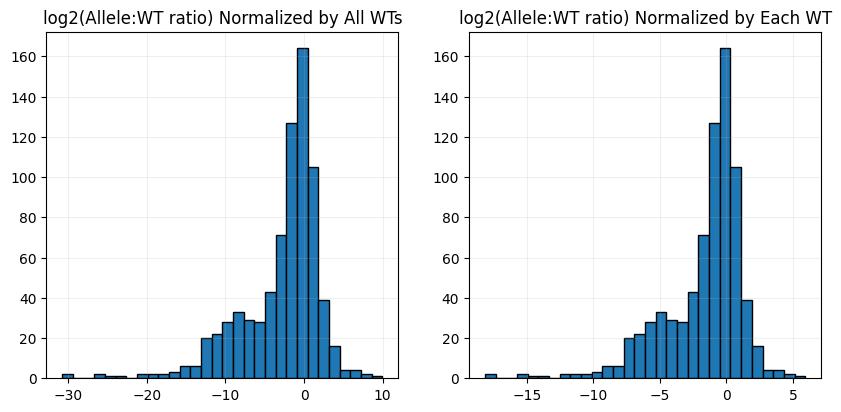

In [38]:
pDEST_DUAL_allele_df = abun_mean.to_pandas()
sig_threshold = 1.96

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_all_wt_mean'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_each_wt'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_all_wt_mean'], bins=30, edgecolor='black')
axes[0].set_title("log2(Allele:WT ratio) Normalized by All WTs")
axes[1].hist(pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_each_wt'], bins=30, edgecolor='black')
axes[1].set_title("log2(Allele:WT ratio) Normalized by Each WT")
axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.show()

The distributions of ```zscore_log2fc_mean_norm_by_all_wt_mean``` and ```zscore_log2fc_mean_norm_by_each_wt``` are almost the same, except for the spread (variation). Normalization by each gene would be more biologically relevant, as it initially captured more variations between WT-WT wells, which led to smaller spread in the Z-score of log2FC's when it was calculated by dividing the std(wt-wt variation).

Go with ```zscore_log2fc_mean_norm_by_each_wt``` eventually.

In [39]:
abun_merged = abun_mean.join(
    abun_median.select(["orf_id", "mut_id"]+[c for c in abun_median.columns if c not in abun_mean.columns]),
    on=["orf_id", "mut_id"],
    how="left"
)

## 3. Pick the final metric for DUAL-IPA abundance change detection

In [40]:
"""
Compare three metrics for pathogenic-vs-benign separation using Polars
- Balanced Accuracy
- AUCPRC
- Balanced-AUPRC
"""

from sklearn.metrics import balanced_accuracy_score, average_precision_score, precision_recall_curve, auc, roc_auc_score
def compute_balanced_auprc(auprc: float, prior: float) -> float:
    """
    Balanced AUPRC (bAUPRC) correcting for class imbalance.
    prior = fraction of positives in the dataset.
    """
    return (auprc * (1 - prior)) / ((auprc * (1 - prior)) + ((1 - auprc) * prior))

# -------------------------------------------------
# 1.  Load your Polars dataframe (replace with real path)
# -------------------------------------------------
df = abun_merged.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(1)
    .otherwise(0)
    .alias("clinvar_label")
)

# -------------------------------------------------
# 2.  Evaluation helper
# -------------------------------------------------
def evaluate_metric(df, col):
    df_clean = df.drop_nulls(subset=col)
    y = df_clean["clinvar_label"].to_numpy()
    scores = df_clean[col].to_numpy()
    prior = y.mean()

    # Balanced accuracy via grid search
    best_ba, best_t = 0, None
    for t in np.unique(scores):
        pred = (scores <= t).astype(int)
        ba = balanced_accuracy_score(y, pred)
        if ba > best_ba:
            best_ba, best_t = ba, t

    # AUROC and AUCPRC
    auroc  = roc_auc_score(y, -scores)
    auprc  = average_precision_score(y, -scores)
    bauprc = compute_balanced_auprc(auprc, prior)
    return {
        "bal_acc": round(best_ba, 5),
        "auroc":   round(auroc, 5),
        "auprc":   round(auprc, 5),
        "bauprc":  round(bauprc, 5),
        "threshold": round(best_t, 5),
    }

# -------------------------------------------------
# 3.  Run for each metric column
# -------------------------------------------------
metric_cols = [
    "zscore_log2fc_mean_norm_by_each_wt",
    "zscore_log2fc_median_norm_by_each_wt",
]

results = {col: evaluate_metric(df, col) for col in metric_cols}

# -------------------------------------------------
# 4.  Report
# -------------------------------------------------
for k, v in results.items():
    print(f"{k}: {v}")

print("\nBest balanced accuracy ->", max(results, key=lambda k: results[k]["bal_acc"]))
print("Best AUROC             ->", max(results, key=lambda k: results[k]["auroc"]))
print("Best AUCPRC            ->", max(results, key=lambda k: results[k]["auprc"]))
print("Best bAUPRC            ->", max(results, key=lambda k: results[k]["bauprc"]))

zscore_log2fc_mean_norm_by_each_wt: {'bal_acc': 0.67886, 'auroc': 0.69442, 'auprc': 0.92853, 'bauprc': 0.72323, 'threshold': -0.63307}
zscore_log2fc_median_norm_by_each_wt: {'bal_acc': 0.67014, 'auroc': 0.6829, 'auprc': 0.92828, 'bauprc': 0.71217, 'threshold': -1.15526}

Best balanced accuracy -> zscore_log2fc_mean_norm_by_each_wt
Best AUROC             -> zscore_log2fc_mean_norm_by_each_wt
Best AUCPRC            -> zscore_log2fc_mean_norm_by_each_wt
Best bAUPRC            -> zscore_log2fc_mean_norm_by_each_wt


In [41]:
abun_merged = abun_merged.with_columns(
    pl.col("zscore_log2fc_mean_norm_by_each_wt").alias("dualipa_abun_score")
)
df_clinvar = abun_merged.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(1)
    .otherwise(0)
    .alias("clinvar_label")
)

In [43]:
abun_merged

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat,allele_wt_log2fc,zscore_log2fc_mean_norm_by_all_wt_mean,allele_wt_log2fc_pvalue,zscore_log2fc_mean_norm_by_each_wt,symbol_right,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change_right,aa_change_right,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,…,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,gene_allele,median_gfp,median_mcherry,median_GFP_mCherry_ratio,wt_GFP_mCherry_ratio_median,allele_wt_ratio_median,zscore_median,zcat_median,zscore_log2fc_median_norm_by_each_wt,dualipa_abun_score
str,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,…,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,str,f64,f64,f64,f64,f64,f64,i64,f64,f64
"""KCNJ2""","""allele""","""899G>A""","""Gly300Asp""",11,"""D07""","""11_D07""",8822,100016069,2641,true,1801.536166,6450.702463,0.526546,1.862762,0.282669,-2.547858,-2,-1.822812,-7.844631,4.3423e-15,-4.608617,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008343""","""ALE00008329""","""NC_000017.11:70175938:G:A""","""899G>A""","""Gly300Asp""","""Edgotyping3""","""VUSMutGDEh010""","""G06""","""GDEhDisVCh_40005""","""F10""",1.0,"""VUSMutGDDh010""","""G06""",…,"""ClinGen:CA329702""",3.0,67588.0,7.0175938e7,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001446813|SCV004571381""","""-""","""-""","""899G>A ""","""Gly300Asp""","""NM_000891.3""",2.0,"""1_Pathogenic""",94.45,0.059524,"""['170390', '609622', '170390']""","""autosomal dominant""","""Rare genetic cardiac disease; …",2,"""ANDERSEN CARDIODYSRHYTHMIC PER…","""KCNJ2_Gly300Asp""",693.679993,5069.049805,0.133067,0.841771,0.15808,-1.875327,-1,-5.589107,-4.608617
"""HBD""","""allele""","""174C>A""","""Asn58Lys""",26,"""E05""","""26_E05""",9609,13796,218146,true,43.352592,5031.259545,0.020272,0.118448,0.171143,-2.93378,-2,-2.546728,-10.990479,4.2467e-28,-6.465333,"""HBD""","""ENSG00000223609""","""CCSBVarC006560""","""ALE00006559""","""NC_000011.10:5234132:G:T""","""174C>A""","""Asn58Lys""","""CEGS2""","""CegsMutGDEh1047""","""D02""","""GDEhDisVCh_40036""","""D03""",2.0,"""CegsMutGDDh1047""","""D02""",…,"""HBVAR:1167,ClinGen:CA124701,Un…",1.0,15081.0,5.234132e6,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000036502""","""-""","""-""","""174C>A ""","""Asn58Lys""","""NM_000519.4""",null,"""5_Others""",98.57,0.076433,null,null,"""Rare genetic hematologic disea…",1,null,"""HBD_Asn58Lys""",33.84,2474.280029,0.012192,0.077713,0.156882,-1.877915,-1,-5.612572,-6.465333
"""SMAD3""","""allele""","""376C>T""","""His126Tyr""",20,"""H03""","""20_H03""",9096,11805,2128,true,2419.451567,5053.17881,0.739225,1.810248,0.408356,-2.11294,-2,-1.292102,-5.538377,3.0529e-8,-3.24744,"""SMAD3""","""ENSG00000166949""","""CCSBVarC007714""","""ALE00007700""","""NC_000015.10:67165064:C:T""","""376C>T""","""His126Tyr""","""Edgotyping3""","""VUSMutGDEh004""","""D11""","""GDEhDisVCh_40014""","""D06""",2.0,"""VUSMutGDDh004""","""D11""",…,"""ClinGen:CA10587872""",2.0,263339.0,6.7165064e7,"""C""","""T""","""-""","""-""","""-

## 4. Finding the threshold for Pathogenic vs Benign

Thresholds were selected by maximising a decision-theoretic utility U = TP – 10*FP – 1*FN, where TP, FP and FN denote true-positive, false-positive and false-negative counts. The 10 : 1 cost ratio was adopted from published health-economic models indicating that the clinical and societal harm of misclassifying a benign variant as pathogenic is approximately ten-fold higher than the harm of missing a true pathogenic variant in this context. The ratio is independent of the observed 7 : 1 class imbalance in the training set.

Empirical studies in genetic-counselling literature estimate the relative societal harm of an FP to be ~10–20× that of an FN (see e.g., Tuffaha et al., 2018, Genetics in Medicine, https://pubmed.ncbi.nlm.nih.gov/29300376/).
Hence we set FP cost = 10 × FN cost in our decision-theoretic utility function.

In [127]:
# abun_merged.filter(
#     pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
# ).select(pl.col("gene_allele", "dualipa_abun_score","clinvar_clnsig_clean")).write_csv("../3_outputs/merged_score.csv")

In [157]:
# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df   = pd.read_csv('../3_outputs/merged_score.csv')
b_scores  = df[df.clinvar_clnsig_clean == '2_Benign']['dualipa_abun_score'].values
p_scores = df[df.clinvar_clnsig_clean == '1_Pathogenic']['dualipa_abun_score'].values
scores = df["dualipa_abun_score"].to_numpy()

X    = df['dualipa_abun_score'].values
ben, path = b_scores, p_scores
labels = pl.DataFrame(df).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
    .then(1)
    .otherwise(0)
    .alias("label")
)["label"].to_numpy()

print(ben.shape, path.shape)
print(b_scores.shape, p_scores.shape)

(70,) (348,)
(70,) (348,)


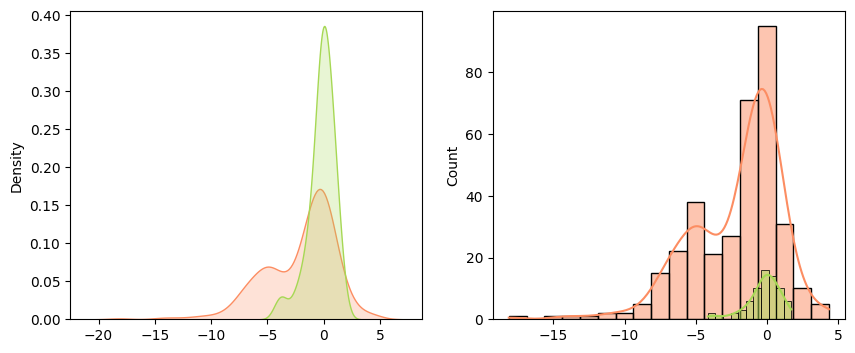

In [151]:
fig, axes = plt.subplots(1,2,figsize=(10, 4))
sns.kdeplot(scores[labels == 1], label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(scores[labels == 0], label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])

sns.histplot(scores[labels == 1], label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores[labels == 0], label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
plt.show()

### 4.1 Cost-sensitive net utility

In [140]:
"""
Imbalanced pathogenic / benign variant scoring
"""
from scipy.stats import mannwhitneyu

def util(tp, fp, fn):
    return tp - FP_w*fp - FN_w*fn
    
# -------------------------------------------------
# 1. Statistical difference
# -------------------------------------------------
u_stat, p_val = mannwhitneyu(p_scores, b_scores, alternative="two-sided")
r = 1 - (2 * u_stat) / (len(p_scores) * len(b_scores))  # rank-biserial

# -------------------------------------------------
# 2. Cost-sensitive threshold optimisation
# -------------------------------------------------
FP_w, FN_w = 10, 1  # clinical cost ratio
min_band   = .5                     # <--- prevent degenerate bands

# single threshold
best_single = max(
    ((t, util(np.sum((labels == 1) & (scores <= t)),
              np.sum((labels == 0) & (scores <= t)),
              np.sum((labels == 1) & (scores >  t))))
     for t in np.unique(scores)),
    key=lambda x: x[1]
)

# three-zone with min-width
best_three = max(
    ((a, b, util(np.sum((labels == 1) & (scores <= a)),
                 np.sum((labels == 0) & (scores <= a)),
                 np.sum((labels == 1) & ((scores > a) & (scores < b)))))
     for a in np.unique(scores)
     for b in np.unique(scores)
     if (b - a) >= min_band),          # <-- guard
    key=lambda x: x[2], default=(None, None, -np.inf)
)

# decide
use_three = best_three[2] > best_single[1] + 5

# -------------------------------------------------
# 4. Final report
# -------------------------------------------------
auroc = roc_auc_score(labels, -scores)  # negative because lower = pathogenic
auprc = average_precision_score(labels, -scores)
prior = labels.mean()
bauprc = compute_balanced_auprc(auprc, prior)

results = {
    "Mann_Whitney_p": p_val,
    "Effect_size_r": r,
    "AUROC": auroc,
    "AUCPRC": auprc,
    "balanced AP": bauprc,
    "Single_thr": best_single[0],
    "Single_util": best_single[1],
    "Three_a": best_three[0],
    "Three_b": best_three[1],
    "Three_util": best_three[2],
    "Use_three_zone": best_three[2] > best_single[1] + 5  # 5 % rule-of-thumb
}
print(results)

{'Mann_Whitney_p': 2.8267019316598356e-07, 'Effect_size_r': 0.3888341543513957, 'AUROC': 0.6944170771756978, 'AUCPRC': 0.9285264744771441, 'balanced AP': 0.7232348226212634, 'Single_thr': -0.6330713054748407, 'Single_util': -100, 'Three_a': -3.8002470302555458, 'Three_b': -3.265192599866845, 'Three_util': 84, 'Use_three_zone': True}


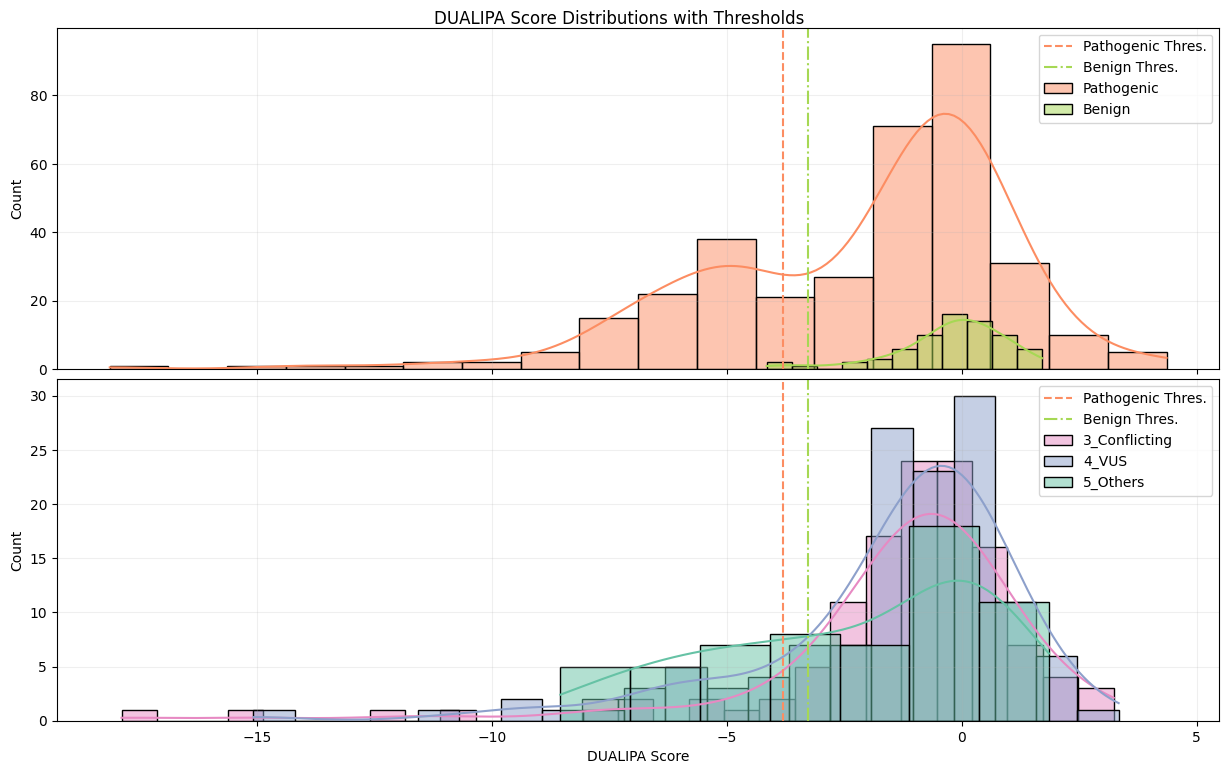

In [141]:
# Plotting
fig, axes = plt.subplots(2,1,figsize=(15, 9),sharex=True)
sns.histplot(scores[labels == 1], label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[0])
sns.histplot(scores[labels == 0], label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[0])

# Plotting thresholds
# plt.axvline(x=results["Single_thr"], color='green', linestyle='--', label='Single Threshold')
axes[0].axvline(x=results["Three_a"], color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].axvline(x=results["Three_b"], color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres.')
axes[0].legend()

sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")["dualipa_abun_score"].to_numpy(), 
            label='3_Conflicting', color=palette_dict["clinvar_clnsig_clean"]["3_Conflicting"], kde=True,  ax=axes[1])
sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")["dualipa_abun_score"].to_numpy(), 
            label='4_VUS', color=palette_dict["clinvar_clnsig_clean"]["4_VUS"], kde=True,  ax=axes[1])
sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "5_Others")["dualipa_abun_score"].to_numpy(), 
            label='5_Others', color=palette_dict["clinvar_clnsig_clean"]["5_Others"], kde=True,  ax=axes[1])

# Plotting thresholds
# plt.axvline(x=results["Single_thr"], color='green', linestyle='--', label='Single Threshold')
axes[1].axvline(x=results["Three_a"], color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].axvline(x=results["Three_b"], color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres.')

# Enhancing plot aesthetics
plt.suptitle('DUALIPA Score Distributions with Thresholds', y=.9)
axes[1].set_xlabel('DUALIPA Score')
# plt.ylabel('Density')
plt.legend()
axes[0].grid(True, alpha=.2)
axes[1].grid(True, alpha=.2)
plt.subplots_adjust(hspace=.03)
plt.show()

### 4.2 Matthews corrcoef (supposedly not affected by class imbalance)

In [166]:
import numpy as np
from sklearn.metrics import roc_curve, matthews_corrcoef

# y_true: 1 for pathogenic, 0 for benign
# scores: your raw scores (lower = more pathogenic in our case)
# so we'll predict pathogenic when score < thr

df   = pd.read_csv('../3_outputs/merged_score.csv')
b_scores  = df[df.clinvar_clnsig_clean == '2_Benign']['dualipa_abun_score'].values
p_scores = df[df.clinvar_clnsig_clean == '1_Pathogenic']['dualipa_abun_score'].values
scores = df["dualipa_abun_score"].to_numpy()

# Invert if needed so that higher → more likely pathogenic:
scores_pos = -scores

# Compute all candidate thresholds on the ROC support
fpr, tpr, thr = roc_curve(labels, scores_pos)

best_mcc = -1
best_threshold = None

# Evaluate MCC at each threshold
for t in thr:
    preds = (scores_pos >= t).astype(int)   # 1 if predicted pathogenic
    mcc = matthews_corrcoef(labels, preds)
    if mcc > best_mcc:
        best_mcc = mcc
        best_threshold = t

# Convert back to original score scale if you inverted:
final_thr = -best_threshold

print(f"Optimal threshold = {final_thr:.3f}, MCC = {best_mcc:.3f}")

X    = df['dualipa_abun_score'].values
# ------------------------------------------------------------------
# 5. Simple confusion matrix
# ------------------------------------------------------------------
pred = np.where(X < final_thr, 'Pathogenic', 'Uncertain/Benign')
cm = pd.crosstab(df.clinvar_clnsig_clean, pred)
print("\nConfusion")
print(cm)

Optimal threshold = -0.633, MCC = 0.268

Confusion
col_0                 Pathogenic  Uncertain/Benign
clinvar_clnsig_clean                              
1_Pathogenic                 208               140
2_Benign                      17                53


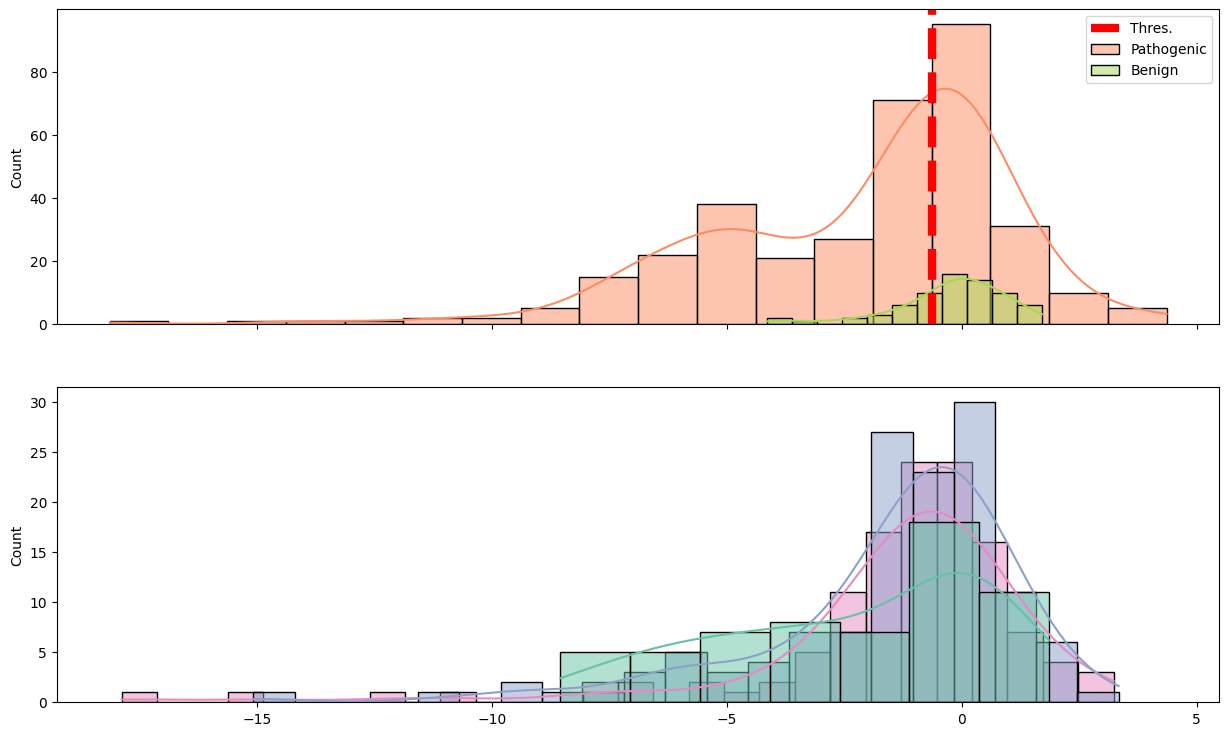

In [173]:
fig, axes = plt.subplots(2,1,figsize=(15, 9),sharex=True)
sns.histplot(scores[labels == 1], label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[0])
sns.histplot(scores[labels == 0], label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[0])

# Plotting thresholds
# plt.axvline(x=results["Single_thr"], color='green', linestyle='--', label='Single Threshold')
axes[0].axvline(x=final_thr, color="red", linestyle='--', label='Thres.', lw=6)
axes[0].legend()

sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")["dualipa_abun_score"].to_numpy(), 
            label='3_Conflicting', color=palette_dict["clinvar_clnsig_clean"]["3_Conflicting"], kde=True,  ax=axes[1])
sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")["dualipa_abun_score"].to_numpy(), 
            label='4_VUS', color=palette_dict["clinvar_clnsig_clean"]["4_VUS"], kde=True,  ax=axes[1])
sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean") == "5_Others")["dualipa_abun_score"].to_numpy(), 
            label='5_Others', color=palette_dict["clinvar_clnsig_clean"]["5_Others"], kde=True,  ax=axes[1])
plt.show()

### 4.3 Gaussian Mixture Model

In [158]:
import pandas as pd
import numpy as np
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity

# 1. Load data
df   = pd.read_csv('../3_outputs/merged_score.csv')
ben  = b_scores.reshape(-1, 1)
path = p_scores.reshape(-1, 1)

def fit_gmm_and_report(data, label):
    """Fit 1-3 component GMMs to `data`, then report AIC, BIC, ΔBIC, and relative evidence."""
    aic_list, bic_list, models = [], [], []
    for n in [1, 2, 3]:
        gm = GaussianMixture(n_components=n, random_state=0)
        gm.fit(data)
        aic_list.append(gm.aic(data))
        bic_list.append(gm.bic(data))
        models.append(gm)
    # Compute ΔBIC and relative evidence
    best_bic = min(bic_list)
    bic_diff = [b - best_bic for b in bic_list]
    evidence = [np.exp(-0.5 * d) for d in bic_diff]
    # Print summary
    print(f"\n{label} GMM fit comparison:")
    for n, (aic, bic, Δ, ev) in enumerate(zip(aic_list, bic_list, bic_diff, evidence), start=1):
        print(f" {n}-component: AIC={aic:.1f}, BIC={bic:.1f}, ΔBIC={Δ:.1f}, relative evidence={ev:.3f}")
    return models

# Fit and report for both categories
gmm_ben = fit_gmm_and_report(ben, "Benign")
gmm_path = fit_gmm_and_report(path, "Pathogenic")


Benign GMM fit comparison:
 1-component: AIC=225.7, BIC=230.2, ΔBIC=4.7, relative evidence=0.093
 2-component: AIC=214.2, BIC=225.4, ΔBIC=0.0, relative evidence=1.000
 3-component: AIC=220.1, BIC=238.1, ΔBIC=12.7, relative evidence=0.002

Pathogenic GMM fit comparison:
 1-component: AIC=1799.0, BIC=1806.7, ΔBIC=92.6, relative evidence=0.000
 2-component: AIC=1694.9, BIC=1714.1, ΔBIC=0.0, relative evidence=1.000
 3-component: AIC=1686.7, BIC=1717.6, ΔBIC=3.4, relative evidence=0.178


In [161]:
"""
One-sided pathogenic threshold via Bayes-factor calibration
----------------------------------------------------------
Uses a GMM for each class, draws synthetic benign samples to
build the null distribution of logBF, and returns the score
cut-off that keeps the family-wise error rate ≤ 0.05.
"""

import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture

df   = pd.read_csv('../3_outputs/merged_score.csv')

# ------------------------------------------------------------------
# 2. Fit 2-component GMMs
# ------------------------------------------------------------------
gmm_ben  = GaussianMixture(n_components=2, random_state=0).fit(ben.reshape(-1, 1))
gmm_path = GaussianMixture(n_components=2, random_state=0).fit(path.reshape(-1, 1))

def logBF(x):
    """log2 Bayes factor: Pathogenic vs Benign"""
    lp = gmm_path.score_samples([[x]])[0]
    lb = gmm_ben.score_samples([[x]])[0]
    return (lp - lb) / np.log(2)

# ------------------------------------------------------------------
# 3. Empirical null of logBF under H0: "variant is benign"
# ------------------------------------------------------------------
n_null = 100_000
synthetic = gmm_ben.sample(n_null)[0].ravel()
null_logBF = np.array([logBF(v) for v in synthetic])

# one-sided Bonferroni alpha
alpha  = 0.05 / len(X)
cutoff = np.quantile(null_logBF, alpha)      # left-tail critical logBF
print(f"Critical logBF (one-sided, α={alpha:.1e}): {cutoff:.2f}")

# ------------------------------------------------------------------
# ROC curve on likelihood-ratio scores
# ------------------------------------------------------------------
scores_sorted = np.array([logBF(v) for v in X])
y_true = (df.clinvar_clnsig_clean == '1_Pathogenic').astype(int)

# descending order: more negative logBF => stronger pathogenic evidence
desc_idx = np.argsort(scores_sorted)          # ascending
scores_sorted = scores_sorted[desc_idx]
y_true_sorted = y_true.values[desc_idx]

# cumulate TPR / FPR
tpr = np.cumsum(y_true_sorted) / y_true.sum()
fpr = np.cumsum(1 - y_true_sorted) / (1 - y_true).sum()

# choose the threshold that gives 95 % specificity (FPR = 0.05)
idx95 = np.where(fpr <= 0.05)[0][-1]   # last index with FPR ≤ 5 %
a = X[desc_idx][idx95]                 # back to original score scale
print(f"ROC-based threshold @ 95 % specificity: a = {a:.3f}")

# ------------------------------------------------------------------
# 4. Build grid that definitely covers the left tail
#    (sample points from benign GMM below its 1st percentile)
# ------------------------------------------------------------------
left_tail = np.percentile(synthetic, 0.5)
low, high = left_tail, X.max()
grid = np.linspace(low, high, 5000)

llrs = np.array([logBF(v) for v in grid])
idx  = np.where(llrs < cutoff)[0]
a = grid[idx[-1]] if idx.size else grid[0]
print(f"Pathogenic threshold →  score < {a:.3f}")

# ------------------------------------------------------------------
# 5. Simple confusion matrix
# ------------------------------------------------------------------
pred = np.where(X < a, 'Pathogenic', 'Uncertain/Benign')
cm = pd.crosstab(df.clinvar_clnsig_clean, pred)
print("\nConfusion")
print(cm)

Critical logBF (one-sided, α=1.2e-04): -1.23
ROC-based threshold @ 95 % specificity: a = 0.605
Pathogenic threshold →  score < -4.458

Confusion
col_0                 Pathogenic  Uncertain/Benign
clinvar_clnsig_clean                              
1_Pathogenic                  87               261
2_Benign                       0                70


Crossing(s): [-0.907  1.74 ]


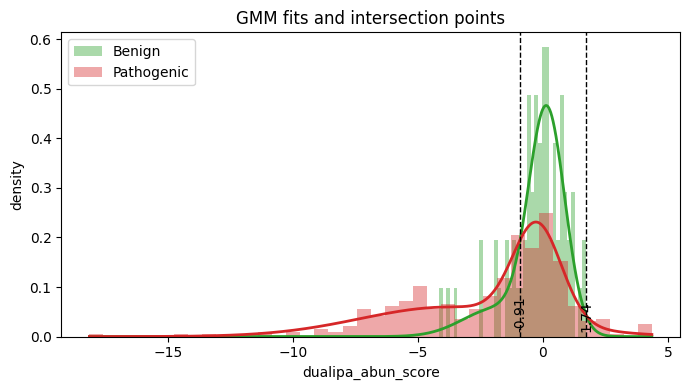


Confusion
col_0                 Pathogenic  Uncertain/Benign
clinvar_clnsig_clean                              
1_Pathogenic                 186               162
2_Benign                      14                56


In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from scipy.optimize import brentq

# ------------------------------------------------------------------
# 1. load data
# ------------------------------------------------------------------
df   = pd.read_csv('../3_outputs/merged_score.csv')
ben  = df[df.clinvar_clnsig_clean == '2_Benign']['dualipa_abun_score'].values
path = df[df.clinvar_clnsig_clean == '1_Pathogenic']['dualipa_abun_score'].values

# ------------------------------------------------------------------
# 2. fit 2-component GMMs
# ------------------------------------------------------------------
gmm_b  = GaussianMixture(n_components=2, random_state=0).fit(ben.reshape(-1, 1))
gmm_p  = GaussianMixture(n_components=2, random_state=0).fit(path.reshape(-1, 1))

# ------------------------------------------------------------------
# 3. helper: vectorised PDF
# ------------------------------------------------------------------
def pdf(x, gmm):
    x = np.asarray(x).reshape(-1, 1)
    return np.exp(gmm.score_samples(x))

def diff(x):
    return pdf(x, gmm_b) - pdf(x, gmm_p)

# ------------------------------------------------------------------
# 4. locate crossings on a dense grid
# ------------------------------------------------------------------
x_min = min(ben.min(), path.min())
x_max = max(ben.max(), path.max())
xs = np.linspace(x_min, x_max, 5000)

d = diff(xs)
sign_flip = np.where(np.diff(np.sign(d)))[0]

crossings = []
for idx in sign_flip:
    a, b = xs[idx], xs[idx + 1]
    try:
        crossings.append(brentq(lambda x: float(diff(x)), a, b))
    except ValueError:
        pass
crossings = np.round(crossings, 3)
print("Crossing(s):", crossings)

# ------------------------------------------------------------------
# 5. plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,4))

# histograms (normalised)
plt.hist(ben,  bins=40, alpha=0.4, label='Benign', density=True, color='tab:green')
plt.hist(path, bins=40, alpha=0.4, label='Pathogenic', density=True, color='tab:red')

# fitted GMM curves
ys_b = pdf(xs, gmm_b)
ys_p = pdf(xs, gmm_p)
plt.plot(xs, ys_b, color='tab:green', lw=2)
plt.plot(xs, ys_p, color='tab:red',   lw=2)

# vertical lines at the crossings
for c in crossings:
    plt.axvline(c, color='k', ls='--', lw=1)
    plt.text(c, 0.01, f'{c:.2f}', rotation=90, va='bottom', ha='center')

plt.xlabel('dualipa_abun_score')
plt.ylabel('density')
plt.title('GMM fits and intersection points')
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 5. Simple confusion matrix
# ------------------------------------------------------------------
pred = np.where(X < crossings[0], 'Pathogenic', 'Uncertain/Benign')
cm = pd.crosstab(df.clinvar_clnsig_clean, pred)
print("\nConfusion")
print(cm)

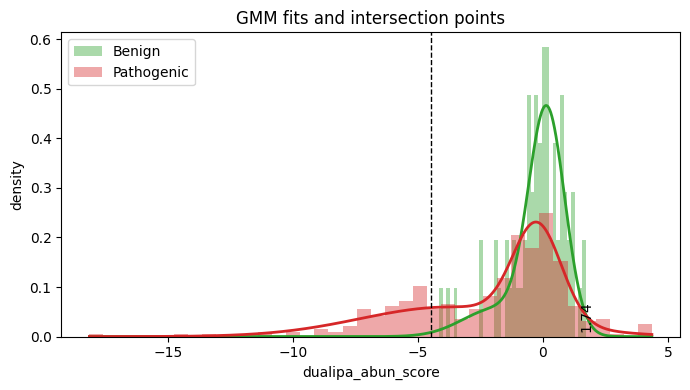

In [165]:
# ------------------------------------------------------------------
# 5. plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,4))

# histograms (normalised)
plt.hist(ben,  bins=40, alpha=0.4, label='Benign', density=True, color='tab:green')
plt.hist(path, bins=40, alpha=0.4, label='Pathogenic', density=True, color='tab:red')

# fitted GMM curves
ys_b = pdf(xs, gmm_b)
ys_p = pdf(xs, gmm_p)
plt.plot(xs, ys_b, color='tab:green', lw=2)
plt.plot(xs, ys_p, color='tab:red',   lw=2)

# vertical lines at the crossings
plt.axvline(-4.458, color='k', ls='--', lw=1)
plt.text(c, 0.01, f'{c:.2f}', rotation=90, va='bottom', ha='center')

plt.xlabel('dualipa_abun_score')
plt.ylabel('density')
plt.title('GMM fits and intersection points')
plt.legend()
plt.tight_layout()
plt.show()

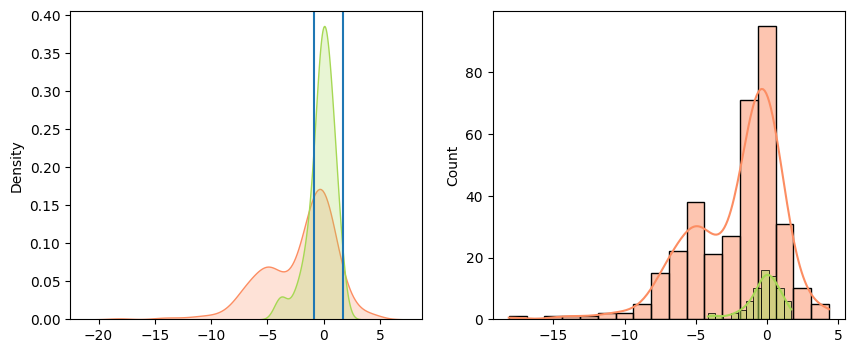

In [125]:
fig, axes = plt.subplots(1,2,figsize=(10, 4))
sns.kdeplot(path, label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(ben, label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(crossings[0])
axes[0].axvline(crossings[1])

sns.histplot(path, label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(ben, label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
plt.show()

### 

1. Bayesian prior to the distribution, 

2. Discriminative approach:

   2.1 Boundary for separating class 1 vs class 2

   2.2  

In [16]:
abun_merged = abun_merged.with_columns(
    pl.when(pl.col("dualipa_abun_score")<=results["Three_a"])
    .then(pl.lit(1))
    .when(pl.col("dualipa_abun_score")>results["Three_b"])
    .then(pl.lit(0))
    .otherwise(-1)
    .alias("dualipa_abun_change")
).with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
    pl.col("clinvar_clnsig_clean").fill_null("6_No_ClinVar")
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("RSA_Category"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("pLDDT_Category")
)

abun_merged.write_csv("../3_outputs/annotated_perturbation_scores.csv")